# Topic Extraction from Restaurant Reviews (NMF vs. LDA)


## 1. Imports


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from langdetect import detect, DetectorFactory
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import NMF, LatentDirichletAllocation
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel


## 2. Load and inspect the data


In [2]:
df = pd.read_csv("Restaurant_Reviews.tsv", sep="\t")
df.columns = df.columns.str.strip().str.lower()
print(df.shape)
print(df.isna().sum())
print("duplicates:", df.duplicated().sum())
print(df["liked"].value_counts())
print(df["review"].str.split().str.len().describe())
df.sample(10, random_state=1)


(1000, 2)
review    0
liked     0
dtype: int64
duplicates: 4
liked
1    500
0    500
Name: count, dtype: int64
count    1000.000000
mean       10.894000
std         6.257469
min         1.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        32.000000
Name: review, dtype: float64


,review,liked
507,My gyro was basically lettuce only.,0
818,It kept getting worse and worse so now I'm off...,0
452,I am far from a sushi connoisseur but I can de...,0
368,"The staff are great, the ambiance is great.",1
242,By this time our side of the restaurant was al...,0
929,Disappointing experience.,0
262,The restaurant atmosphere was exquisite.,1
810,The server was very negligent of our needs and...,0
318,And considering the two of us left there very ...,1
49,My side Greek salad with the Greek dressing wa...,1


## 3. Remove missing values and duplicates, keep English only


In [3]:
df = df.dropna(subset=["review"]).drop_duplicates(subset="review")
print("after dedupe:", df.shape)

DetectorFactory.seed = 0

def detect_lang(t):
    try:
        return detect(t)
    except Exception:
        return "unk"

df["lang"] = df["review"].apply(detect_lang)
print(df["lang"].value_counts().head(10))

df = df[df["lang"] == "en"].copy()
print(df["liked"].value_counts())


after dedupe: (996, 2)
lang
en    960
af      9
fr      6
nl      4
da      3
de      2
so      2
ca      2
ro      2
no      1
Name: count, dtype: int64
liked
1    482
0    478
Name: count, dtype: int64


## 4. Text cleaning


In [4]:
nltk.download("stopwords", quiet=True); nltk.download("wordnet", quiet=True)

stop = set(stopwords.words("english")) | {
    "restaurant", "place", "food", "get", "would", "one",
    "really", "also", "go", "make", "even", "much", "thing"}
lem = WordNetLemmatizer()

def clean(t):
    t = re.sub(r"http\S+|www\.\S+|&\w+;", " ", t.lower())
    t = re.sub(r"[^a-z\s]", " ", t)
    t = re.sub(r"(.){2,}", r"", t)
    return " ".join(lem.lemmatize(w) for w in t.split()
                    if w not in stop and len(w) > 2)

df["clean"] = df["review"].apply(clean)
df = df[df["clean"].str.split().str.len() >= 2].reset_index(drop=True)

print(df["liked"].value_counts())
df[["review", "clean"]].sample(5, random_state=2)


liked
1    452
0    446
Name: count, dtype: int64


,review,clean
874,What happened next was pretty....off putting.,happened next pretty putting
589,It was just not a fun experience.,fun experience
749,I recently tried Caballero's and I have been b...,recently tried caballero back every week since
471,"Similarly, the delivery man did not say a word...",similarly delivery man say word apology minute...
322,As always the evening was wonderful and the fo...,always evening wonderful delicious


## 5. Vectorization 1: TF-IDF


In [5]:
tfidf = TfidfVectorizer(max_df=0.5, min_df=2, ngram_range=(1, 2))
X_tfidf = tfidf.fit_transform(df["clean"])

density = X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1])
print("TF-IDF shape:", X_tfidf.shape, "| non-zero share:", f"{density:.3%}")


TF-IDF shape: (898, 873) | non-zero share: 0.524%


## 6. Vectorization 2: Sentence-BERT embeddings


In [6]:
sbert = SentenceTransformer("all-MiniLM-L6-v2")
X_emb = sbert.encode(df["review"].tolist(), batch_size=64, show_progress_bar=True)
print("Embedding shape:", X_emb.shape)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Embedding shape: (898, 384)


## 7. Comparing the two vectorizations (nearest-neighbour spot check)


In [7]:
i = df.index[df["liked"] == 0][0]
print("QUERY:", df.loc[i, "review"][:200], "\n")

for name, X in [("TF-IDF", X_tfidf), ("SBERT", X_emb)]:
    sims = cosine_similarity(X[i:i+1], X).ravel()
    top = sims.argsort()[::-1][1:4]
    print(f"--- {name} nearest reviews ---")
    for j in top:
        print(f"{sims[j]:.2f} | {df.loc[j, 'review'][:150]}")


QUERY: Crust is not good. 

--- TF-IDF nearest reviews ---
0.45 | The Macarons here are insanely good.
0.45 | Not good by any stretch of the imagination.
0.45 | Their chow mein is so good!
--- SBERT nearest reviews ---
0.65 | Gave up trying to eat any of the crust (teeth still sore).
0.51 | Now the burgers aren't as good, the pizza which used to be amazing is doughy and flavorless.
0.50 | The pizza tasted old, super chewy in not a good way.


## 8. Negative subset with extra stop words. The dataset contains restaurant reviews. A custom list removes common generic terms to highlight specific topics in negative reviews.


In [8]:
extra = {w.replace("'", "") for w in stopwords.words("english")} | {
    "people", "think", "know", "dont", "time", "year", "got", "way", "still",
    "never", "actually", "want", "see", "need", "say", "tell", "look", "going",
    "said", "guy", "man", "thing", "something", "someone", "good", "bad",
    "feel", "take", "first", "work", "day", "made", "fact", "lot"}

neg = df[df["liked"] == 0].reset_index(drop=True)
print("negative reviews:", len(neg))

neg["clean2"] = neg["clean"].apply(lambda t: " ".join(w for w in t.split() if w not in extra))
neg = neg[neg["clean2"].str.split().str.len() >= 2].reset_index(drop=True)
print("after extra stop words:", len(neg))

texts = [t.split() for t in neg["clean2"]]
dictionary = Dictionary(texts)

tf = TfidfVectorizer(max_df=0.3, min_df=2); Xt = tf.fit_transform(neg["clean2"])
cv = CountVectorizer(max_df=0.3, min_df=2);  Xc = cv.fit_transform(neg["clean2"])
print("vocab size:", Xt.shape[1])


negative reviews: 446
after extra stop words: 429
vocab size: 377


## 9. Helper functions


In [9]:
def top_words(model, names, n=10):
    return [[names[j] for j in c.argsort()[-n:][::-1]] for c in model.components_]

def report(model, X, names, label):
    W = model.transform(X)
    dom = W.argmax(1)
    dom[W.sum(1) == 0] = -1          
    print(f"\n===== {label} =====")
    for t, comp in enumerate(model.components_):
        words = [names[j] for j in comp.argsort()[-10:][::-1]]
        share = (dom == t).mean()
        rep = neg["review"][W[:, t].argmax()][:160]
        print(f"\nTopic {t} ({share:.1%} of reviews)")
        print("  words:", ", ".join(words))
        print("  e.g.:", rep)
    print(f"\nunassigned: {(dom == -1).mean():.1%}")


## 10. Choosing the number of topics


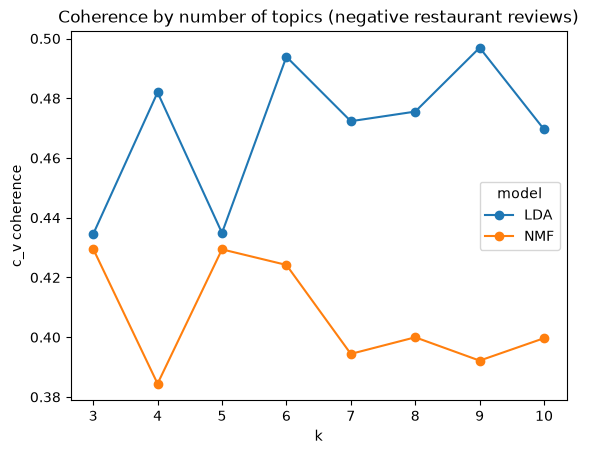

model    LDA    NMF
k                  
3      0.435  0.430
4      0.482  0.384
5      0.435  0.429
6      0.494  0.424
7      0.472  0.394
8      0.476  0.400
9      0.497  0.392
10     0.470  0.400


In [10]:
rows = []
for k in range(3, 11):
    nmf_k = NMF(n_components=k, init="nndsvd", random_state=42, max_iter=500).fit(Xt)
    lda_k = LatentDirichletAllocation(n_components=k, random_state=42, max_iter=20).fit(Xc)
    for name, m, names in [("NMF", nmf_k, tf.get_feature_names_out()),
                           ("LDA", lda_k, cv.get_feature_names_out())]:
        c = CoherenceModel(topics=top_words(m, names), texts=texts,
                           dictionary=dictionary, coherence="c_v",
                           processes=1).get_coherence()
        rows.append((name, k, c))

res = pd.DataFrame(rows, columns=["model", "k", "coherence"])
table = res.pivot(index="k", columns="model", values="coherence")
table.plot(marker="o")
plt.ylabel("c_v coherence"); plt.title("Coherence by number of topics (negative restaurant reviews)")
plt.savefig("coherence_restaurant.png", dpi=200, bbox_inches="tight")
plt.show()
print(table.round(3))


## 11. Final models and topic reports. NMF k=7 and LDA k=6 / k=9 give the strongest coherence values for the negative restaurant reviews.


In [11]:
nmf = NMF(n_components=7, init="nndsvd", random_state=42, max_iter=500).fit(Xt)
lda9 = LatentDirichletAllocation(n_components=9, random_state=42, max_iter=20).fit(Xc)
lda7 = LatentDirichletAllocation(n_components=7, random_state=42, max_iter=20).fit(Xc)

report(nmf,  Xt, tf.get_feature_names_out(), "NMF k=7")
report(lda9, Xc, cv.get_feature_names_out(), "LDA k=9")
report(lda7, Xc, cv.get_feature_names_out(), "LDA k=7")



===== NMF k=7 =====

Topic 0 (10.7% of reviews)
  words: service, slow, terrible, poor, customer, suck, best, mediocre, little, extremely
  e.g.: The service here leaves a lot to be desired.

Topic 1 (10.0% of reviews)
  words: back, probably, soon, anytime, coming, impressed, needless, ever, long, came
  e.g.: Anyway, I do not think i will go back there.

Topic 2 (9.6% of reviews)
  words: ever, worst, tasted, eat, experience, hard, sushi, thai, dish, overpriced
  e.g.: The plantains were the worst I've ever tasted.

Topic 3 (12.1% of reviews)
  words: like, chip, friend, wanted, restaurant, blow, could, eat, probably, pay
  e.g.: The only thing I wasn't too crazy about was their guacamole as I don't like it puréed.

Topic 4 (14.9% of reviews)
  words: minute, waited, another, wait, took, table, waiting, acknowledged, order, kept
  e.g.: We waited for forty five minutes in vain.

Topic 5 (10.3% of reviews)
  words: star, give, disappointed, zero, deserves, possible, hard, review, two

## 12. Figure: NMF topic shares. The topic labels were assigned by reading each topic's top words from the negative restaurant reviews.


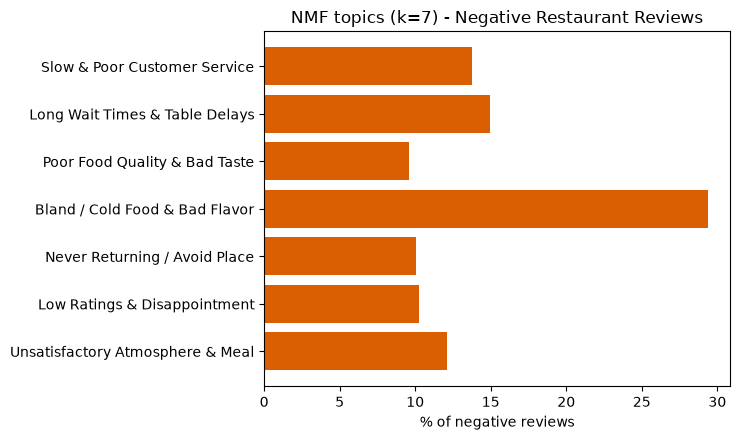

In [12]:
topic_labels = {
    0: "Slow & Poor Customer Service",
    1: "Never Returning / Avoid Place",
    2: "Poor Food Quality & Bad Taste",
    3: "Unsatisfactory Atmosphere & Meal",
    4: "Long Wait Times & Table Delays",
    5: "Low Ratings & Disappointment",
    6: "Bland / Cold Food & Bad Flavor"
}

W = nmf.transform(Xt)
dom = W.argmax(1)
order = [0, 4, 2, 6, 1, 5, 3]
shares = [(dom == t).mean() * 100 for t in order]

plt.figure(figsize=(7.5, 4.5))
plt.barh([topic_labels[t] for t in order][::-1], shares[::-1], color="#d95f02")
plt.xlabel("% of negative reviews"); plt.title("NMF topics (k=7) - Negative Restaurant Reviews")
plt.tight_layout()
plt.savefig("nmf_topics_restaurant.png", dpi=200)
plt.show()
